# Vodafone UK Coverage Gap: Stage 4 Prioritisation



In [1]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from scipy import ndimage, stats
from pyproj import Transformer
OUT = Path('/content/drive/MyDrive/vodafone-project/data'); FIG = OUT / 'figures'; FIG.mkdir(exist_ok=True)
INK, INK2, GRID, SURF = '#0b0b0b', '#52514e', '#e6e5e0', '#fcfcfb'
plt.rcParams.update({'font.size': 10, 'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.grid': True, 'grid.color': GRID, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.facecolor': SURF,
    'axes.facecolor': SURF, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.axisbelow': True})
def save(fig, name): fig.savefig(FIG / f'{name}.png', dpi=160, bbox_inches='tight'); plt.show()

X = pd.read_parquet(OUT / 'grid_model_stage3.parquet')
X['gx'] = X.gx.astype(int); X['gy'] = X.gy.astype(int)
lad = gpd.read_file(OUT / 'lad_dec2024_uk.geojson').to_crs(27700)
need = ['cov_in_share_Vodafone', 'cov_in_share_EE', 'cov_in_share_O2', 'cov_in_share_Three', 'cov_in_share_VodafoneThree', 'pop']
print(X.shape, '| missing columns:', [c for c in need if c not in X])

Mounted at /content/drive
(12626, 58) | missing columns: []


## 1. Classify each square

In [2]:
THR = 0.5

def classify(X, thr=THR):
    vo  = X.cov_in_share_Vodafone >= thr
    vt  = X.cov_in_share_VodafoneThree >= thr
    riv = np.maximum(X.cov_in_share_EE, X.cov_in_share_O2) >= thr
    before = np.select([vo, riv], ['Vodafone OK', 'Vodafone-only not-spot'], 'Shared not-spot')
    after  = np.select([vt, riv], ['Covered after merger', 'Remaining: Vodafone-only'], 'Remaining: shared (all weak)')
    return before, after

X['before'], X['after'] = classify(X)
X['fixed_by_merger'] = (X.before != 'Vodafone OK') & (X.after == 'Covered after merger')

tab = pd.crosstab(X.before, X.after, values=X['pop'], aggfunc='sum').fillna(0).round(-2)
print('People living in measured squares, by status before (rows) and after merger (cols):'); display(tab.astype(int))
summary = pd.DataFrame({
    'squares': X.groupby('before').size(),
    'people': X.groupby('before')['pop'].sum().round(-2)}).astype(int)
summary['share_of_squares'] = (summary.squares / len(X)).round(3)
display(summary)
ns = X.before != 'Vodafone OK'
print(f"Vodafone not-spot squares fixed by the merger: {X.loc[ns, 'fixed_by_merger'].mean():.0%} "
      f"({X.loc[ns & X.fixed_by_merger, 'pop'].sum()/1e3:,.0f}k of {X.loc[ns, 'pop'].sum()/1e3:,.0f}k people)")

People living in measured squares, by status before (rows) and after merger (cols):


after,Covered after merger,Remaining: Vodafone-only,Remaining: shared (all weak)
before,,,
Shared not-spot,64200,0,78400
Vodafone OK,9235100,0,0
Vodafone-only not-spot,341200,84700,0


,squares,people,share_of_squares
before,,,
Shared not-spot,872,142600,0.069
Vodafone OK,10055,9235100,0.796
Vodafone-only not-spot,1699,425900,0.135


Vodafone not-spot squares fixed by the merger: 41% (405k of 569k people)


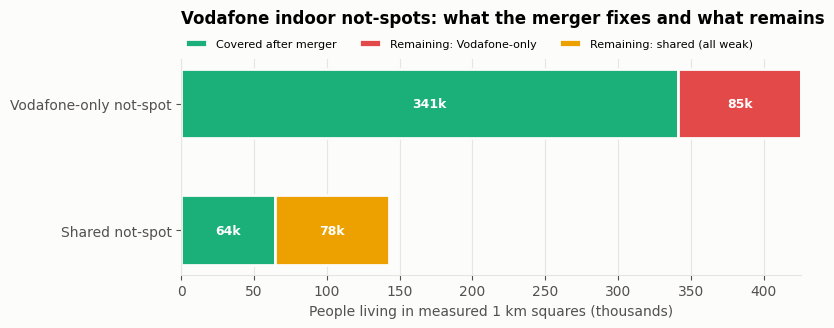

In [3]:

order = ['Covered after merger', 'Remaining: Vodafone-only', 'Remaining: shared (all weak)']
colors = {'Covered after merger': '#1baf7a', 'Remaining: Vodafone-only': '#e34948', 'Remaining: shared (all weak)': '#eda100'}
p = X[ns].groupby(['before', 'after'])['pop'].sum().unstack().reindex(columns=order).fillna(0) / 1e3
fig, ax = plt.subplots(figsize=(8, 2.8))
left = np.zeros(len(p))
for c in order:
    b = ax.barh(p.index, p[c], left=left, color=colors[c], label=c, height=.55, edgecolor=SURF, lw=2)
    for rect, v, l in zip(b, p[c], left):
        if v > p.values.sum() * .08:
            ax.text(l + v / 2, rect.get_y() + rect.get_height() / 2, f'{v:,.0f}k', ha='center', va='center', color='white', fontsize=9, fontweight='bold')
    left += p[c].values
ax.set_xlabel('People living in measured 1 km squares (thousands)'); ax.grid(axis='y', visible=False)
ax.set_title('Vodafone indoor not-spots: what the merger fixes and what remains', pad=26)
ax.legend(ncol=3, frameon=False, loc='lower left', bbox_to_anchor=(-.01, 1.0), fontsize=8)
save(fig, '08_merger_notspot_people')

## 2. Priority score


In [4]:
X['gap_after'] = (np.maximum(X.cov_in_share_EE, X.cov_in_share_O2) - X.cov_in_share_VodafoneThree).clip(lower=0)
X['priority'] = X['pop'] * X.gap_after
X['is_competitive'] = X.after == 'Remaining: Vodafone-only'
X['is_shared'] = X.after == 'Remaining: shared (all weak)'
print('Squares with any remaining gap vs best rival:', (X.gap_after > 0).sum())
print(f"Top 10% of squares hold {X.priority.nlargest(int(len(X)*.1)).sum()/X.priority.sum():.0%} of total priority score")

Squares with any remaining gap vs best rival: 4677
Top 10% of squares hold 94% of total priority score


## 3. Build areas: adjacent remaining not-spot squares grouped together

In [5]:
def build_areas(X, mask, min_pop=0):
    s = X[mask].copy()
    if s.empty:
        return pd.DataFrame(columns=['rank', 'lad_nm', 'squares', 'people', 'priority', 'mean_gap_after', 'vodafone_cov', 'vt_cov',
                                     'best_rival_cov', 'hotspot_share', 'gx', 'gy', 'lat', 'lon']), s
    s['gx'] = s.gx.astype(int); s['gy'] = s.gy.astype(int)
    x0, y0 = int(s.gx.min()) - 1, int(s.gy.min()) - 1
    A = np.zeros((s.gy.max() - y0 + 2, s.gx.max() - x0 + 2), dtype=bool)
    A[s.gy - y0, s.gx - x0] = True
    lab, n = ndimage.label(A, structure=np.ones((3, 3)))
    s = s.assign(area_id=lab[s.gy - y0, s.gx - x0])
    tf = Transformer.from_crs(27700, 4326, always_xy=True)
    agg = s.groupby('area_id').agg(
        squares=('gx', 'size'), people=('pop', 'sum'), priority=('priority', 'sum'),
        mean_gap_after=('gap_after', 'mean'), vodafone_cov=('cov_in_share_Vodafone', 'mean'),
        vt_cov=('cov_in_share_VodafoneThree', 'mean'), best_rival_cov=('cov_in_share_EE', 'mean'),
        lad_nm=('lad_nm', lambda v: v.mode().iat[0]), gx=('gx', 'mean'), gy=('gy', 'mean'),
        hotspot_share=('lisa_gap', lambda v: (v == 'High-High (hotspot)').mean()))
    lon, lat = tf.transform((agg.gx + .5) * 1000, (agg.gy + .5) * 1000)
    agg['lat'], agg['lon'] = np.round(lat, 4), np.round(lon, 4)
    agg = agg[agg.people >= min_pop].sort_values('priority', ascending=False).reset_index()
    agg.insert(0, 'rank', np.arange(1, len(agg) + 1))
    return agg, s

areas_comp, cells_comp = build_areas(X, X.is_competitive)
areas_shared, cells_shared = build_areas(X, X.is_shared)
cols = ['rank', 'lad_nm', 'squares', 'people', 'vodafone_cov', 'vt_cov', 'mean_gap_after', 'hotspot_share', 'lat', 'lon']
print(f'{len(areas_comp)} competitive build areas, {len(areas_shared)} shared areas')
print('\nTop 15 COMPETITIVE build areas (VodafoneThree weak, a rival covers):')
display(areas_comp[cols].head(15).round(3))
areas_comp.to_csv(OUT / 'priority_areas_competitive.csv', index=False)
areas_shared.to_csv(OUT / 'priority_areas_shared.csv', index=False)

398 competitive build areas, 347 shared areas

Top 15 COMPETITIVE build areas (VodafoneThree weak, a rival covers):


,rank,lad_nm,squares,people,vodafone_cov,vt_cov,mean_gap_after,hotspot_share,lat,lon
0,1,Wiltshire,2,4448.499,0.287,0.415,0.380,0.000,51.249,-2.195
1,2,Leeds,2,1751.255,0.000,0.000,1.000,0.000,53.766,-1.600
2,3,County Durham,1,3049.076,0.328,0.328,0.530,0.000,54.768,-1.590
3,4,Reading,1,1383.289,0.058,0.058,0.923,0.000,51.429,-0.973
4,5,Bolton,1,1510.340,0.042,0.042,0.842,0.000,53.554,-2.386
5,6,North Lanarkshire,1,3855.034,0.152,0.397,0.318,0.000,55.848,-4.038
6,7,Stratford-on-Avon,2,1926.306,0.135,0.311,0.594,0.500,52.184,-1.599
7,8,Fife,2,1626.345,0.182,0.184,0.732,0.000,56.222,-2.695
8,9,Leeds,2,2069.747,0.238,0.300,0.431,1.000,53.901,-1.629
9,10,Leeds,1,987.215,0.000,0.038,0.962,0.000,53.760,-1.372


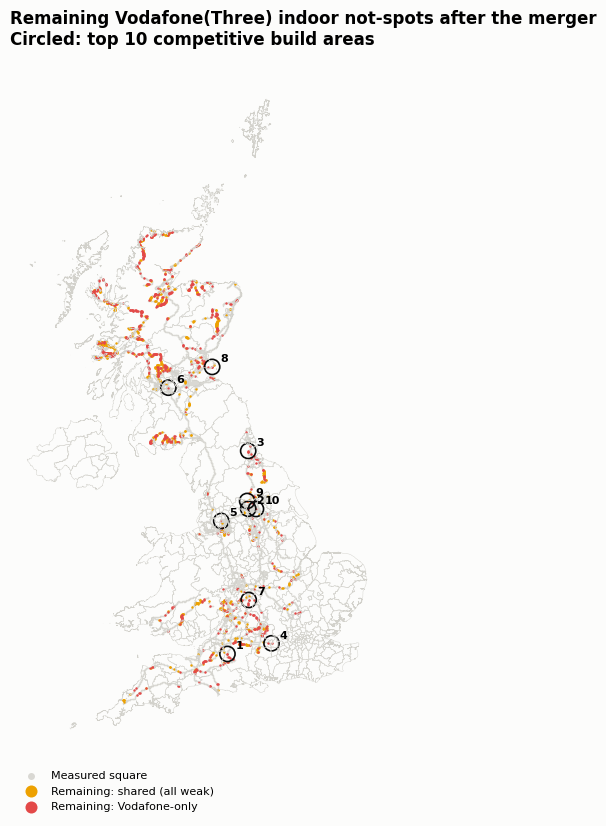

In [6]:
fig, ax = plt.subplots(figsize=(7, 9))
lad.boundary.plot(ax=ax, color='#d2d1cb', lw=.3)
ax.scatter((X.gx + .5) * 1000, (X.gy + .5) * 1000, s=1, color='#d9d8d3', lw=0, label='Measured square')
ax.scatter((cells_shared.gx + .5) * 1000, (cells_shared.gy + .5) * 1000, s=3, color='#eda100', lw=0, label='Remaining: shared (all weak)')
ax.scatter((cells_comp.gx + .5) * 1000, (cells_comp.gy + .5) * 1000, s=3, color='#e34948', lw=0, label='Remaining: Vodafone-only')
top = areas_comp.head(10)
ax.scatter((top.gx + .5) * 1000, (top.gy + .5) * 1000, s=120, facecolor='none', edgecolor=INK, lw=1.2)
for _, r in top.iterrows():
    ax.annotate(f"{int(r['rank'])}", ((r.gx + .5) * 1000, (r.gy + .5) * 1000), xytext=(6, 4), textcoords='offset points', fontsize=8, fontweight='bold')
ax.set_aspect('equal'); ax.axis('off')
ax.set_title('Remaining Vodafone(Three) indoor not-spots after the merger\nCircled: top 10 competitive build areas')
ax.legend(loc='upper left', bbox_to_anchor=(0, 0), frameon=False, markerscale=5, fontsize=8)
save(fig, '09_priority_map')

## 4. Local authority ranking

> ⚠️ **Superseded, kept for transparency.** This first version summed priority over *all* squares, so big cities with many people × tiny gaps (e.g. Manchester) ranked high despite having almost no real not-spots. See section 7 for the corrected ranking.

In [7]:
la = X.groupby(['lad_cd', 'lad_nm']).agg(
    squares=('gx', 'size'),
    people_measured=('pop', 'sum'),
    notspot_people_before=('pop', lambda v: v[X.loc[v.index, 'before'] != 'Vodafone OK'].sum()),
    fixed_by_merger_people=('pop', lambda v: v[X.loc[v.index, 'fixed_by_merger']].sum()),
    competitive_people=('pop', lambda v: v[X.loc[v.index, 'is_competitive']].sum()),
    shared_people=('pop', lambda v: v[X.loc[v.index, 'is_shared']].sum()),
    priority=('priority', 'sum'),
    hotspot_share=('lisa_gap', lambda v: (v == 'High-High (hotspot)').mean())).reset_index()
la['competitive_share'] = la.competitive_people / la.people_measured
la = la[la.squares >= 20].sort_values('priority', ascending=False).reset_index(drop=True)
la.insert(0, 'rank', la.index + 1)
la.to_csv(OUT / 'priority_local_authorities.csv', index=False)
display(la.head(20).round(3))

,rank,lad_cd,lad_nm,squares,people_measured,notspot_people_before,fixed_by_merger_people,competitive_people,shared_people,priority,hotspot_share,competitive_share
0,1,E08000035,Leeds,228,409255.253,42806.509,37790.155,4856.670,159.684,9798.061,0.057,0.012
1,2,E06000047,County Durham,85,53817.832,5898.883,451.596,5447.287,0.000,6476.933,0.059,0.101
2,3,E08000007,Stockport,62,194746.850,4891.590,4648.966,0.000,242.624,5865.774,0.000,0.000
3,4,S12000047,Fife,402,231020.937,23609.513,16507.279,4018.042,3084.192,5428.255,0.149,0.017
4,5,E06000054,Wiltshire,264,102721.344,16790.856,7637.195,6757.171,2396.490,5399.226,0.098,0.066
5,6,E08000019,Sheffield,115,330576.688,4192.018,3846.294,143.459,202.265,5327.825,0.009,0.000
6,7,E06000066,Somerset,399,157677.494,30749.958,23029.464,2341.344,5379.149,4883.706,0.125,0.015
7,8,S12000036,City of Edinburgh,146,438641.095,7576.884,7576.884,0.000,0.000,4293.806,0.000,0.000
8,9,E08000003,Manchester,105,583201.894,32.831,0.000,0.000,32.831,4207.955,0.000,0.000
9,10,S12000017,Highland,1588,145593.559,14913.939,7577.580,3593.195,3743.164,3964.952,0.193,0.025


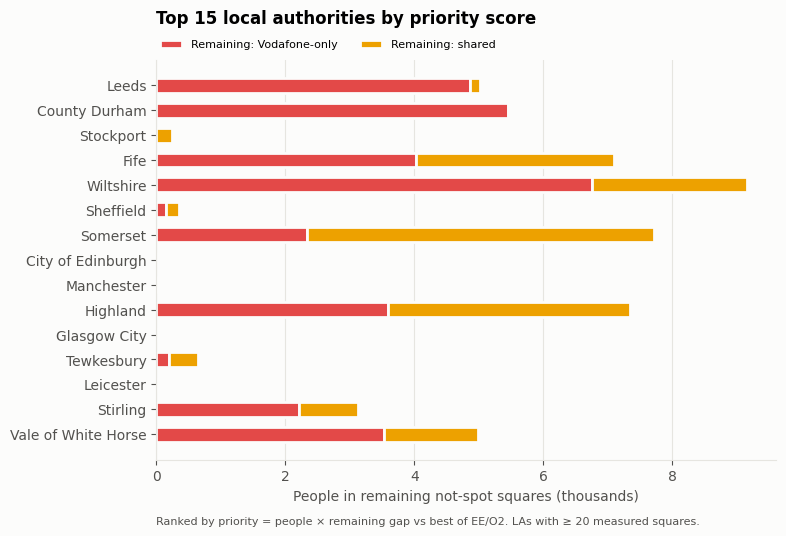

In [8]:
t = la.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(t.lad_nm, t.competitive_people / 1e3, color='#e34948', height=.6, label='Remaining: Vodafone-only', edgecolor=SURF, lw=2)
ax.barh(t.lad_nm, t.shared_people / 1e3, left=t.competitive_people / 1e3, color='#eda100', height=.6, label='Remaining: shared', edgecolor=SURF, lw=2)
ax.grid(axis='y', visible=False); ax.set_xlabel('People in remaining not-spot squares (thousands)')
ax.set_title('Top 15 local authorities by priority score', pad=26)
ax.legend(ncol=2, frameon=False, loc='lower left', bbox_to_anchor=(-.01, 1.0), fontsize=8)
ax.text(0, -.16, 'Ranked by priority = people × remaining gap vs best of EE/O2. LAs with ≥ 20 measured squares.', transform=ax.transAxes, fontsize=8, color=INK2)
save(fig, '10_top15_la_priority')

## 5. Sensitivity: does the ranking change with the threshold?

In [9]:
ranks = {}
for thr in (0.3, 0.5, 0.7):
    b, a = classify(X, thr)
    pr = (X['pop'] * X.gap_after).where(a == 'Remaining: Vodafone-only', 0)
    ranks[thr] = pr.groupby(X.lad_nm).sum()
R = pd.DataFrame(ranks)
R = R[R.index.isin(la.lad_nm)]
print('Spearman rank correlation of LA competitive priority between thresholds:')
display(R.corr('spearman').round(2))
top10 = {thr: set(R[thr].nlargest(10).index) for thr in R}
print('Top-10 overlap 0.5 vs 0.3:', len(top10[.5] & top10[.3]), '/10 | 0.5 vs 0.7:', len(top10[.5] & top10[.7]), '/10')

Spearman rank correlation of LA competitive priority between thresholds:


,0.3,0.5,0.7
0.3,1.00,0.73,0.65
0.5,0.73,1.00,0.72
0.7,0.65,0.72,1.00


Top-10 overlap 0.5 vs 0.3: 8 /10 | 0.5 vs 0.7: 7 /10


## 6. Notes for the write-up


In [10]:
X.to_parquet(OUT / 'grid_priority_stage4.parquet')
print('Saved: priority_areas_competitive.csv, priority_areas_shared.csv, priority_local_authorities.csv, grid_priority_stage4.parquet')

Saved: priority_areas_competitive.csv, priority_areas_shared.csv, priority_local_authorities.csv, grid_priority_stage4.parquet


## 7. Corrected local authority ranking and build-area filter
Ranks local authorities on priority from squares that **remain Vodafone-only not-spots** after the merger, and flags isolated single squares (often tunnels, cuttings or measurement faults) instead of ranking them. **These are the results used in the README.**

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Top 15 LAs by COMPETITIVE priority (remaining Vodafone-only not-spots):


,rank,lad_nm,squares,competitive_squares,competitive_people,shared_people,fixed_by_merger_people,competitive_priority
0,1,Leeds,228,7,4857.0,160.0,37790.0,3702.0
1,2,Wiltshire,264,25,6757.0,2396.0,7637.0,3177.0
2,3,County Durham,85,9,5447.0,0.0,452.0,2945.0
3,4,Vale of White Horse,133,13,3531.0,1455.0,1512.0,2201.0
4,5,Highland,1588,241,3593.0,3743.0,7578.0,1784.0
5,6,Fife,402,23,4018.0,3084.0,16507.0,1678.0
6,7,Stratford-on-Avon,108,9,2813.0,1149.0,6241.0,1569.0
7,8,Somerset,399,22,2341.0,5379.0,23029.0,1412.0
8,9,South Oxfordshire,77,7,3493.0,259.0,5600.0,1224.0
9,10,Stockton-on-Tees,27,5,3797.0,0.0,839.0,1127.0



146 ranked build areas (>=2 squares), 252 single squares flagged to verify


,rank,lad_nm,squares,people,vodafone_cov,vt_cov,mean_gap_after,lat,lon
0,1,Wiltshire,2,4448.499,0.287,0.415,0.380,51.249,-2.195
1,2,Leeds,2,1751.255,0.000,0.000,1.000,53.766,-1.600
6,3,Stratford-on-Avon,2,1926.306,0.135,0.311,0.594,52.184,-1.599
7,4,Fife,2,1626.345,0.182,0.184,0.732,56.222,-2.695
8,5,Leeds,2,2069.747,0.238,0.300,0.431,53.901,-1.629
10,6,South Oxfordshire,2,2590.674,0.092,0.351,0.381,51.593,-1.236
11,7,Somerset,4,1088.232,0.157,0.211,0.741,51.125,-2.816
13,8,Stockton-on-Tees,6,1319.133,0.061,0.223,0.662,54.639,-1.343
14,9,Vale of White Horse,2,1473.172,0.111,0.219,0.458,51.706,-1.314
16,10,Vale of White Horse,3,1066.466,0.120,0.232,0.767,51.569,-1.234


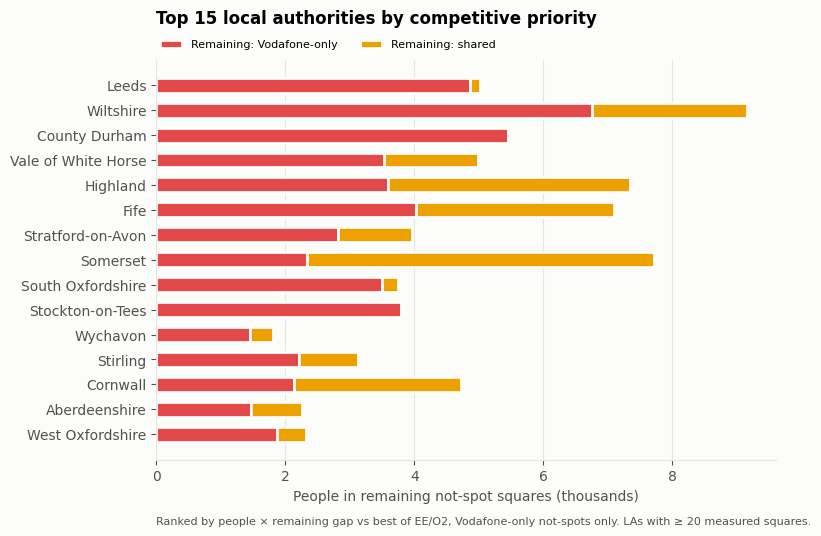

In [11]:

from google.colab import drive; drive.mount('/content/drive')
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
OUT = Path('/content/drive/MyDrive/vodafone-project/data'); FIG = OUT / 'figures'
X = pd.read_parquet(OUT / 'grid_priority_stage4.parquet')
X['prio_comp'] = X.priority.where(X.is_competitive, 0)
X['prio_shared'] = X.priority.where(X.is_shared, 0)

la = X.groupby(['lad_cd', 'lad_nm']).agg(
    squares=('gx', 'size'), people_measured=('pop', 'sum'),
    competitive_squares=('is_competitive', 'sum'), shared_squares=('is_shared', 'sum'),
    competitive_people=('pop', lambda v: v[X.loc[v.index, 'is_competitive']].sum()),
    shared_people=('pop', lambda v: v[X.loc[v.index, 'is_shared']].sum()),
    fixed_by_merger_people=('pop', lambda v: v[X.loc[v.index, 'fixed_by_merger']].sum()),
    competitive_priority=('prio_comp', 'sum'), shared_priority=('prio_shared', 'sum')).reset_index()
la = la[(la.squares >= 20) & (la.competitive_squares >= 2)]
la = la.sort_values('competitive_priority', ascending=False).reset_index(drop=True)
la.insert(0, 'rank', la.index + 1)
la.to_csv(OUT / 'priority_local_authorities.csv', index=False)
print('Top 15 LAs by COMPETITIVE priority (remaining Vodafone-only not-spots):')
display(la.head(15)[['rank', 'lad_nm', 'squares', 'competitive_squares', 'competitive_people', 'shared_people',
                     'fixed_by_merger_people', 'competitive_priority']].round(0))

areas = pd.read_csv(OUT / 'priority_areas_competitive.csv')
areas['status'] = np.where(areas.squares >= 2, 'ranked', 'single square: verify (tunnel/cutting?)')
ranked = areas[areas.squares >= 2].copy(); ranked['rank'] = np.arange(1, len(ranked) + 1)
pd.concat([ranked, areas[areas.squares < 2].assign(rank=np.nan)]).to_csv(OUT / 'priority_areas_competitive.csv', index=False)
print(f'\n{len(ranked)} ranked build areas (>=2 squares), {(areas.squares < 2).sum()} single squares flagged to verify')
display(ranked.head(15)[['rank', 'lad_nm', 'squares', 'people', 'vodafone_cov', 'vt_cov', 'mean_gap_after', 'lat', 'lon']].round(3))

t = la.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(t.lad_nm, t.competitive_people / 1e3, color='#e34948', height=.6, label='Remaining: Vodafone-only', edgecolor='#fcfcfb', lw=2)
ax.barh(t.lad_nm, t.shared_people / 1e3, left=t.competitive_people / 1e3, color='#eda100', height=.6, label='Remaining: shared', edgecolor='#fcfcfb', lw=2)
ax.grid(axis='y', visible=False); ax.set_xlabel('People in remaining not-spot squares (thousands)')
ax.set_title('Top 15 local authorities by competitive priority', loc='left', fontweight='bold', pad=26)
ax.legend(ncol=2, frameon=False, loc='lower left', bbox_to_anchor=(-.01, 1.0), fontsize=8)
ax.text(0, -.16, 'Ranked by people × remaining gap vs best of EE/O2, Vodafone-only not-spots only. LAs with ≥ 20 measured squares.',
        transform=ax.transAxes, fontsize=8, color='#52514e')
fig.savefig(FIG / '10_top15_la_priority.png', dpi=160, bbox_inches='tight'); plt.show()